### <font color = "gold"> Import les librairies requises

In [1]:
# Importer les packages
import pandas as pd
import numpy as np
import plotly.express as px

In [2]:
 # Supprimer les warnings
 import warnings
 warnings.filterwarnings('ignore')

### <font color = "gold"> Importer et lire les données

In [3]:
df= pd.read_csv('wheat_seeds_dataset.csv')

**Nous avons ici des données de graines de blé. Chaque graine de blé est caractérisée par 7 variables morphologiques (issues de l'étude morphologique de chaque graine).**

**Source :** UCI Machine Learning Repository, dataset « seeds »
- Page du dataset : https://archive.ics.uci.edu/dataset/236/seeds
- Téléchargement direct : https://archive.ics.uci.edu/static/public/236/seeds.zip
- Fichier utilisé : wheat_seeds_dataset.csv, soit 199 des 210 graines du fichier seeds_dataset.txt (3 variétés de blé : Kama, Rosa et Canadian), avec les 7 variables morphologiques et sans la colonne de variété

In [4]:
# Afficher les données
df.head()

,area A,perimeter,compactness,length of kernel,width of kernel,asymmetry coefficient,length of kernel groove
0,15.26,14.84,0.8710,5.763,3.312,2.221,5.220
1,14.88,14.57,0.8811,5.554,3.333,1.018,4.956
2,14.29,14.09,0.9050,5.291,3.337,2.699,4.825
3,13.84,13.94,0.8955,5.324,3.379,2.259,4.805
4,16.14,14.99,0.9034,5.658,3.562,1.355,5.175


In [5]:
# Dimension des données
df.shape

(199, 7)

In [6]:
# Infos des données
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 199 entries, 0 to 198
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   area A                   199 non-null    float64
 1   perimeter                199 non-null    float64
 2   compactness              199 non-null    float64
 3   length of kernel         199 non-null    float64
 4   width of kernel          199 non-null    float64
 5   asymmetry coefficient    199 non-null    float64
 6   length of kernel groove  199 non-null    float64
dtypes: float64(7)
memory usage: 11.0 KB


In [7]:
# Décrire les données
df.describe()

,area A,perimeter,compactness,length of kernel,width of kernel,asymmetry coefficient,length of kernel groove
count,199.000000,199.000000,199.000000,199.000000,199.000000,199.000000,199.000000
mean,14.918744,14.595829,0.870811,5.643151,3.265533,3.699217,5.420653
std,2.919976,1.310445,0.023320,0.443593,0.378322,1.471102,0.492718
min,10.590000,12.410000,0.808100,4.899000,2.630000,0.765100,4.519000
25%,12.330000,13.470000,0.857100,5.267000,2.954500,2.570000,5.046000
50%,14.430000,14.370000,0.873400,5.541000,3.245000,3.631000,5.228000
75%,17.455000,15.805000,0.886800,6.002000,3.564500,4.799000,5.879000
max,21.180000,17.250000,0.918300,6.675000,4.033000,8.315000,6.550000


In [8]:
# Renommer les index
for i in range(len(df)):
    df.rename(index={i: f"Seed_{i+1}"}, inplace=True)

df.head()


,area A,perimeter,compactness,length of kernel,width of kernel,asymmetry coefficient,length of kernel groove
Seed_1,15.26,14.84,0.8710,5.763,3.312,2.221,5.220
Seed_2,14.88,14.57,0.8811,5.554,3.333,1.018,4.956
Seed_3,14.29,14.09,0.9050,5.291,3.337,2.699,4.825
Seed_4,13.84,13.94,0.8955,5.324,3.379,2.259,4.805
Seed_5,16.14,14.99,0.9034,5.658,3.562,1.355,5.175


In [9]:
# Matrice des données
x = df.values
x[0:5]

array([[15.26  , 14.84  ,  0.871 ,  5.763 ,  3.312 ,  2.221 ,  5.22  ],
       [14.88  , 14.57  ,  0.8811,  5.554 ,  3.333 ,  1.018 ,  4.956 ],
       [14.29  , 14.09  ,  0.905 ,  5.291 ,  3.337 ,  2.699 ,  4.825 ],
       [13.84  , 13.94  ,  0.8955,  5.324 ,  3.379 ,  2.259 ,  4.805 ],
       [16.14  , 14.99  ,  0.9034,  5.658 ,  3.562 ,  1.355 ,  5.175 ]])

#### <font color = "gold"> Appliquer une ACP

In [10]:
# Importer PCA
from sklearn.decomposition import PCA
#Instantier le modèle PCA avec n_components = 2
pca = PCA(n_components=2)
# Entrainer le modèle
features_pca = pca.fit_transform(x)
# Matrice des 2 composantes
features_pca[:5]
# Dataframe
New_df = pd.DataFrame(features_pca, columns = ['PCA1', 'PCA2'])

In [11]:
# Part de variance des 2 composantes
round(sum(pca.explained_variance_ratio_*100),2)

np.float64(99.3)

### <font color = "gold"> Kmeans

In [12]:
# Importer KMeans
from sklearn.cluster import KMeans

##### <font color = "bisque"> La méthode elbow(coude)

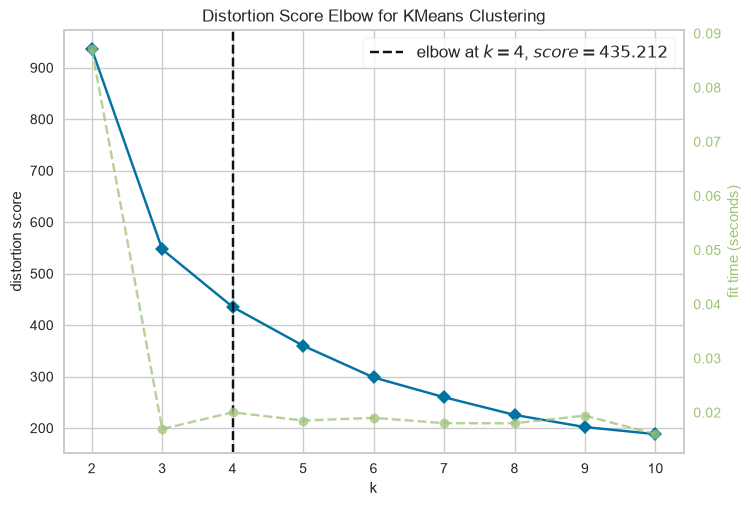

<Axes: title={'center': 'Distortion Score Elbow for KMeans Clustering'}, xlabel='k', ylabel='distortion score'>

In [13]:
# importer KELbowVisualizer
import setuptools  # charge le module distutils de remplacement pour yellowbrick
from yellowbrick.cluster import KElbowVisualizer
# Instantier le modèle kmeans
kmeans_model = KMeans(init = 'random', max_iter=500)
kmeans_model._estimator_type = "clusterer"  # contournement : yellowbrick 1.5 + scikit-learn ≥ 1.6
# Instantier KELbowVisualizer
Elbow_M = KElbowVisualizer(kmeans_model, k=10)
# Entrainement
Elbow_M.fit(x)
# Visualiser l'elbow
Elbow_M.show()

**Choix de k = 3.** Le coude proposé par KElbowVisualizer (k = 4) est peu marqué. On retient k = 3 : c'est le nombre de variétés de blé du dataset UCI, et l'indice de silhouette est meilleur pour 3 classes (≈ 0,47) que pour 4 (≈ 0,42).

#### <font color = "bisque"> Appliquer Kmeans en utilisant le k optimal

In [14]:
# Initier le modèle
kmeans_model = KMeans(n_clusters = 3, init = 'random', max_iter=500, random_state=42)
# Entrainer le modèle
kmeans_model.fit(x)

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",3
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'random'
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",'auto'
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",500
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary `.",42
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'


#### <font color = "bisque"> Prédiction la partition

In [15]:
# Prediction de la partition(l'ensemble des classes) de X
Pred = kmeans_model.predict(x)
# Afficher la partition
Pred

array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 1, 1, 2, 1, 1, 1,
       1, 1, 1, 2, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 2, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 1, 1, 1, 1, 2,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 0, 1,
       1, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 1, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2], dtype=int32)

In [16]:
# Nombre d'observations dans chaque classe
val = pd.Series(Pred).value_counts()
val

2    72
1    67
0    60
Name: count, dtype: int64

In [17]:
# Diagramme en barre du nombre d'observations dans chaque classe
fig = px.bar(x = val.index.astype(str), y = val.values, color = val.index.astype(str), text_auto = True)
fig.show()

#### <font color = "bisque"> Visualiser les classes prédictes par Kmeans

In [18]:
# Visualiser les classes suivant les deux composantes en utilisant plotly.express
fig = px.scatter(New_df, x = 'PCA1', y = 'PCA2', color = Pred.astype(str))
fig.show()

<font color = "bisque">Indice de silhouette value de la partition du Kmeans

In [19]:
# Importer silhouette score
from sklearn.metrics import silhouette_score
# Indice de Silhouette value
siil_kmeans = silhouette_score(x, Pred)
print("Silhouette score for KMeans clustering: ", siil_kmeans)

Silhouette score for KMeans clustering:  0.4727232858211619


In [20]:
# Les graines de chaque classes
cluster_name = []
for i in range(3):
    cluster_name.append(list(df.index[Pred == i]))

In [21]:
# Afficher les graines de la classe 0
print("Graines de la classe 0 :")
print(cluster_name[0])

Graines de la classe 0 :
['Seed_36', 'Seed_67', 'Seed_68', 'Seed_69', 'Seed_70', 'Seed_71', 'Seed_72', 'Seed_73', 'Seed_74', 'Seed_75', 'Seed_76', 'Seed_77', 'Seed_78', 'Seed_79', 'Seed_80', 'Seed_81', 'Seed_82', 'Seed_83', 'Seed_84', 'Seed_85', 'Seed_86', 'Seed_87', 'Seed_88', 'Seed_89', 'Seed_90', 'Seed_91', 'Seed_92', 'Seed_93', 'Seed_94', 'Seed_95', 'Seed_96', 'Seed_98', 'Seed_99', 'Seed_100', 'Seed_101', 'Seed_102', 'Seed_103', 'Seed_104', 'Seed_105', 'Seed_106', 'Seed_107', 'Seed_108', 'Seed_109', 'Seed_110', 'Seed_111', 'Seed_112', 'Seed_113', 'Seed_114', 'Seed_115', 'Seed_116', 'Seed_117', 'Seed_119', 'Seed_121', 'Seed_122', 'Seed_123', 'Seed_124', 'Seed_125', 'Seed_126', 'Seed_127', 'Seed_131']


### <font color = "gold"> CAH

In [22]:
# Importer linkage et dendrogram
from scipy.cluster.hierarchy import  linkage, dendrogram

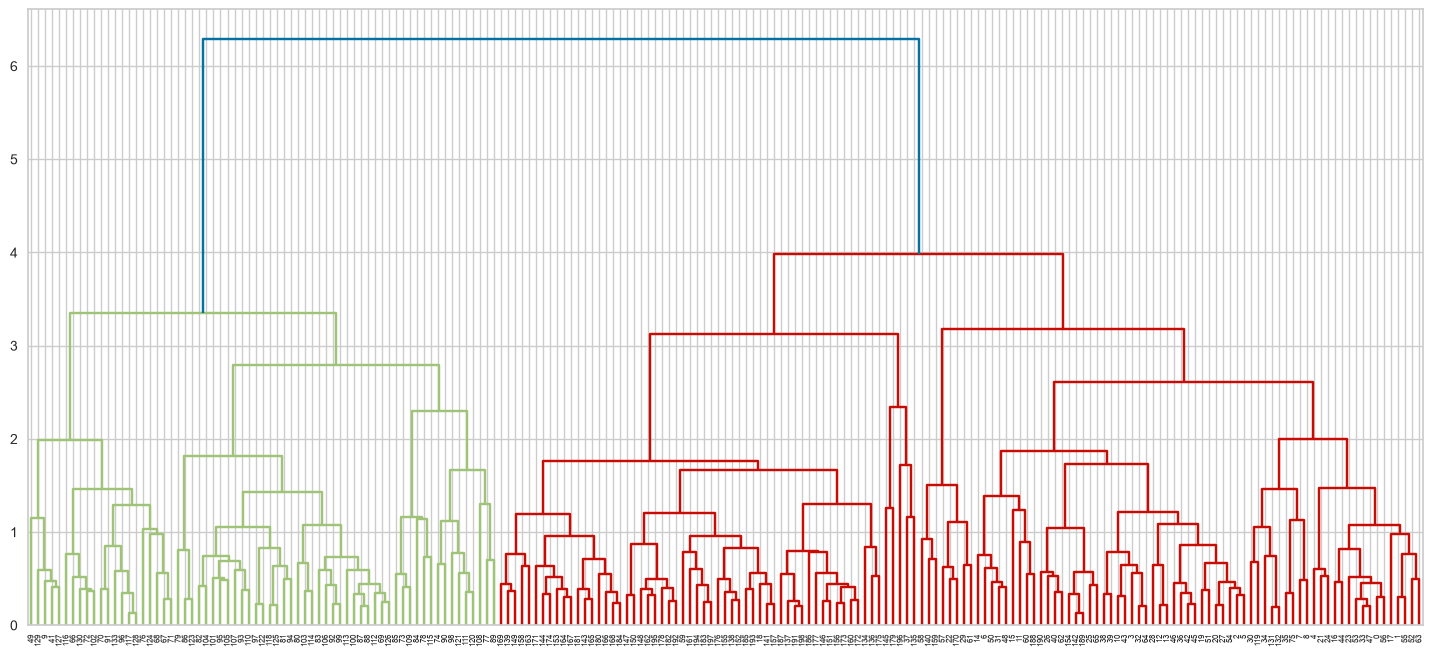

In [23]:
# Visualiser le dendrograme
import matplotlib.pyplot as plt
Z = linkage(x, 'average')# matrice des liaisons
plt.figure(figsize=(18, 8))
dendro = dendrogram(Z, leaf_font_size=6, orientation = 'top')

In [24]:
from sklearn.cluster import AgglomerativeClustering
# Initier AgglomerativeClustering
cah_model = AgglomerativeClustering(n_clusters = 3, linkage = 'average')
# Entrainer le modèle
cah_model.fit(x)

,"n_clusters n_clusters: int or None, default=2The number of clusters to find. It must be ``None`` if``distance_threshold`` is not ``None``.",3
,"metric metric: str or callable, default=""euclidean""Metric used to compute the linkage. Can be ""euclidean"", ""l1"", ""l2"",""manhattan"", ""cosine"", or ""precomputed"". If linkage is ""ward"", only""euclidean"" is accepted. If ""precomputed"", a distance matrix is neededas input for the fit method. If connectivity is None, linkage is""single"" and affinity is not ""precomputed"" any valid pairwise distancemetric can be assigned.For an example of agglomerative clustering with different metrics, see:ref:`sphx_glr_auto_examples_cluster_plot_agglomerative_clustering_metrics.py`... versionadded:: 1.2",'euclidean'
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the output of the computation of the tree.By default, no caching is done. If a string is given, it is thepath to the caching directory.",None
,"connectivity connectivity: array-like, sparse matrix, or callable, default=NoneConnectivity matrix. Defines for each sample the neighboringsamples following a given structure of the data.This can be a connectivity matrix itself or a callable that transformsthe data into a connectivity matrix, such as derived from`kneighbors_graph`. Default is ``None``, i.e, thehierarchical clustering algorithm is unstructured.For an example of connectivity matrix using:class:`~sklearn.neighbors.kneighbors_graph`, see:ref:`sphx_glr_auto_examples_cluster_plot_ward_structured_vs_unstructured.py`.",None
,"compute_full_tree compute_full_tree: 'auto' or bool, default='auto'Stop early the construction of the tree at ``n_clusters``. This isuseful to decrease computation time if the number of clusters is notsmall compared to the number of samples. This option is useful onlywhen specifying a connectivity matrix. Note also that when varying thenumber of clusters and using caching, it may be advantageous to computethe full tree. It must be ``True`` if ``distance_threshold`` is not``None``. By default `compute_full_tree` is ""auto"", which is equivalentto `True` when `distance_threshold` is not `None` or that `n_clusters`is inferior to the maximum between 100 or `0.02 * n_samples`.Otherwise, ""auto"" is equivalent to `False`.",'auto'
,"linkage linkage: {'ward', 'complete', 'average', 'single'}, default='ward'Which linkage criterion to use. The linkage criterion determines whichdistance to use between sets of observation. The algorithm will mergethe pairs of cluster that minimize this criterion.- 'ward' minimizes the variance of the clusters being merged.- 'average' uses the average of the distances of each observation of the two sets.- 'complete' or 'maximum' linkage uses the maximum distances between all observations of the two sets.- 'single' uses the minimum of the distances between all observations of the two sets... versionadded:: 0.20 Added the 'single' optionFor examples comparing different `linkage` criteria, see:ref:`sphx_glr_auto_examples_cluster_plot_linkage_comparison.py`.",'average'
,"distance_threshold distance_threshold: float, default=NoneThe linkage distance threshold at or above which clusters will not bemerged. If not ``None``, ``n_clusters`` must be ``None`` and``compute_full_tree`` must be ``True``... versionadded:: 0.21",None
,"compute_distances compute_distances: bool, default=FalseComputes distances between clusters even if `distance_threshold` is notused. This can be used to make dendrogram visualization, but introducesa computational and memory overhead... versionadded:: 0.24For an example of dendrogram visualization, see:ref:`sphx_glr_auto_examples_cluster_plot_agglomerative_dendrogram.py`.",False


#### <font color = "bisque"> Prédiction la partition

In [25]:
# Prédire la partition des données
cah_partition = cah_model.fit_predict(x)
# Afficher la partition
cah_partition

array([1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 2, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 1, 1, 1, 0, 1, 1,
       1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 1, 1, 1, 1, 1, 1,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1,
       1, 0, 2, 2, 2, 2, 2, 2, 1, 2, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       1, 2, 2, 2, 2, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 1, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 1, 1, 1, 2, 2, 2, 2, 2, 2, 2,
       2])

In [26]:
# Nombre d'observations dans chaque classe
val1  = pd.Series(cah_partition).value_counts()
val1

1    72
0    67
2    60
Name: count, dtype: int64

In [27]:
# Diagramme en barre des nombres d'observations
fig = px.bar(x = val1.index.astype(str), y = val1.values, color = val1.index.astype(str), text_auto = True)
fig.show()

#### <font color = "bisque"> Visualiser les classes prédictes par la CAH

In [28]:
# Visualiser les classes suivant les deux composantes
fig = px.scatter(New_df, x = 'PCA1', y = 'PCA2', color = cah_partition.astype(str))
fig.show()

<font color = "bisque">Indice de silhouette value de la partition de la CAH

In [29]:
# Silhouette score
sil_cah = silhouette_score(x, cah_partition)
print("Silhouette score for Agglomerative clustering: ", sil_cah)

Silhouette score for Agglomerative clustering:  0.44381623615602017


### <font color = "gold"> Comparaison K-Means / CAH

In [30]:
# Diagrammes en barre des silhouettes
Model_Names = ['KMEANS', 'CAH']
sil = [siil_kmeans, sil_cah]
fig = px.bar(x= Model_Names, y = sil, color = Model_Names, text_auto = True)
fig.show()

In [31]:
# Classes K-Means / classes CAH : combien de graines sont regroupées de la même façon ?
pd.crosstab(Pred, cah_partition, rownames=['Classe K-Means'], colnames=['Classe CAH'])

Classe CAH,0,1,2
Classe K-Means,,,
0,58,2,0
1,9,58,0
2,0,12,60


##### <font color = "bisque"> Conclusion de la comparaison

- **Silhouette** : K-Means ≈ 0,473 contre ≈ 0,444 pour la CAH ; les classes du K-Means sont un peu plus compactes et mieux séparées.
- **Effectifs** : 60 / 67 / 72 graines pour le K-Means, 67 / 72 / 60 pour la CAH : on retrouve trois groupes de tailles proches (les numéros des classes ne se correspondent pas d'un modèle à l'autre).
- **Accord des deux partitions** : le tableau croisé montre que 176 graines sur 199 (≈ 88 %) sont regroupées de la même façon. Les désaccords (9 + 12 + 2 graines) se situent à la frontière entre deux groupes, visible sur le plan (PCA1, PCA2).
- Les deux méthodes trouvent donc la même structure : des graines **grandes**, **moyennes** et **petites**. On retient le **K-Means**, qui a la meilleure silhouette, pour le déploiement.

### <font color = "gold"> Déploiement du meilleur modèle (K-Means) avec Streamlit

In [32]:
from scipy.spatial.distance import cdist

# Calculer les centroïdes
classes = np.unique(Pred)
centroides = np.array([x[Pred == c].mean(axis=0) for c in classes])

# Prédiction : la classe du centroïde le plus proche
# (les données ne sont pas normalisées dans ce notebook)
def predire_classe(nouvelle_graine):
    graine = np.array(nouvelle_graine, dtype=float).reshape(1, -1)
    distances = cdist(graine, centroides)
    return classes[distances.argmin()]

In [33]:
# Test rapide
print("Classe prédite  :", predire_classe(df.iloc[0].values))
print("Classe réelle du K-Means:", Pred[0])

Classe prédite  : 1
Classe réelle du K-Means: 1


#### <font color = "bisque"> Interpréter les classes

Avant de livrer l'application, il faut savoir **ce que représente chaque classe**, pour afficher un
message compréhensible par l'utilisateur final. On regarde le profil moyen de chaque classe.

In [34]:
# Profil moyen de chaque classe
profil = df.groupby(Pred).mean().round(2)
profil

,area A,perimeter,compactness,length of kernel,width of kernel,asymmetry coefficient,length of kernel groove
0,18.72,16.30,0.88,6.21,3.72,3.62,6.06
1,14.66,14.47,0.88,5.57,3.28,2.66,5.19
2,11.99,13.29,0.85,5.24,2.88,4.73,5.10


La classe 0 regroupe les plus grosses graines (aire ≈ 18,7), la classe 1 les graines moyennes (≈ 14,7) et la classe 2 les plus petites (≈ 12,0), plus asymétriques.

In [35]:
# Noms des classes
noms_classes = {
    0: "grain de blé de grande taille",
    1: "grain de blé de taille moyenne",
    2: "grain de blé de petite taille",
}

In [36]:
# Sauvegarder le modèle pour l'application Streamlit
# (la PCA sert seulement à visualiser les classes dans le plan PCA1, PCA2)
import joblib
joblib.dump({'modele': 'K-Means', 'variables': list(df.columns), 'classes': classes,
             'centroides': centroides, 'noms_classes': noms_classes, 'pca': pca, 'normalize': False},
            'wheat_clustering.joblib')

['wheat_clustering.joblib']